# 01 Environment exploration

Shared SUMO / sumo-rl setup used by every controller. Environments come from `src/envs/make_env.py` (3600 s, `delta_time=5`). Outputs are summaries and small plots.

## 1. Versions

In [3]:
import os
import subprocess
import sys
from importlib.metadata import version
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import sumo

os.environ.setdefault("SUMO_HOME", sumo.SUMO_HOME)
sumo_bin = Path(os.environ["SUMO_HOME"]) / "bin" / "sumo"
sumo_line = subprocess.check_output([str(sumo_bin), "--version"], text=True).splitlines()[0]
print(sumo_line)
print("sumo-rl", version("sumo-rl"))
print("pettingzoo", version("pettingzoo"))
print("stable-baselines3", version("stable-baselines3"))

Eclipse SUMO sumo 1.27.1
sumo-rl 1.4.5
pettingzoo 1.27.0
stable-baselines3 2.9.2


## 2. Agents, actions, observations, lanes

`single` and `grid4x4` through `make_env`. Action size is the number of green phases. Lanes are the incoming lanes sumo-rl controls for one signal.

In [5]:
from src.envs.make_env import make_env


def sumo_environment(env):
    current = env
    seen = set()
    while current is not None and id(current) not in seen:
        seen.add(id(current))
        if hasattr(current, "traffic_signals"):
            return current
        current = getattr(current, "aec_env", None) or getattr(current, "env", None)
    raise RuntimeError("SUMO environment not found under the PettingZoo wrappers")


def episode_finished(truncated):
    return isinstance(truncated, dict) and bool(truncated) and all(truncated.values())


def describe(scenario):
    env = make_env(scenario, seed=0, additional_sumo_cmd="--no-step-log")
    try:
        env.reset(seed=0)
        inner = sumo_environment(env)
        agent = env.agents[0]
        signal = inner.traffic_signals[agent]
        action_sizes = {a: int(env.action_space(a).n) for a in env.agents}
        obs_dim = int(env.observation_space(agent).shape[0])
        print(f"{scenario}: {len(env.agents)} agents")
        print(f"  action space size (green phases): {sorted(set(action_sizes.values()))} for every agent" if len(set(action_sizes.values())) == 1 else f"  action space sizes: {action_sizes}")
        print(f"  observation dimension ({agent}): {obs_dim}")
        print(f"  controlled lanes ({agent}): {signal.lanes}")
        return {
            "agents": list(env.agents),
            "action_sizes": action_sizes,
            "obs_dim": obs_dim,
            "lanes": list(signal.lanes),
            "route": inner._route,
        }
    finally:
        env.close()


scenario_info = {name: describe(name) for name in ("single", "grid4x4")}

 Retrying in 1 seconds
 Retrying in 1 seconds
single: 1 agents
  action space size (green phases): [2] for every agent
  observation dimension (t): 11
  controlled lanes (t): ['n_t_0', 'n_t_1', 'w_t_0', 'w_t_1']
 Retrying in 1 seconds
 Retrying in 1 seconds
grid4x4: 16 agents
  action space size (green phases): [8] for every agent
  observation dimension (A0): 33
  controlled lanes (A0): ['A1A0_0', 'A1A0_1', 'A1A0_2', 'B0A0_0', 'B0A0_1', 'B0A0_2', 'bottom0A0_0', 'bottom0A0_1', 'bottom0A0_2', 'left0A0_0', 'left0A0_1', 'left0A0_2']


/opt/homebrew/Caskroom/miniconda/base/envs/traffic/lib/python3.11/site-packages/pettingzoo/utils/conversions.py:129: UserWarning: The base environment `sumo_rl_v0` does not have a `render_mode` defined.
  warnings.warn(


## 3. Route files

Count vehicles and flows in the default route used by `make_env`. The histogram covers the 3600 s episode. Flows store a rate rather than one depart time per vehicle, so their bars are expected departures (`probability` per second, or `vehsPerHour`).

single: 0 vehicles (0 depart in [0, 3600)), 2 flows
  flow flow_ns: begin=0 end=100000 probability=0.2 vehsPerHour=None
  flow flow_we: begin=0 end=100000 probability=0.5 vehsPerHour=None
  expected vehicles in 3600s: 2520
grid4x4: 1473 vehicles (1473 depart in [0, 3600)), 0 flows


cell_7:73: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


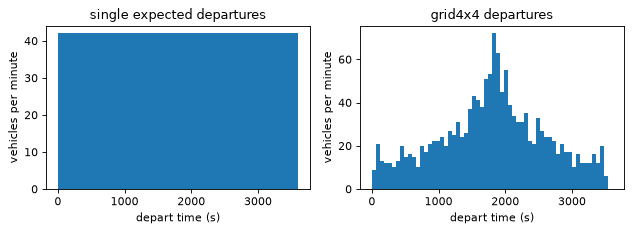

In [7]:
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.figsize"] = (6, 3)
plt.rcParams["figure.dpi"] = 80

HORIZON = 3600
BIN_S = 60


def parse_route(path):
    vehicles = 0
    departures = []
    flows = []
    for _event, elem in ET.iterparse(path, events=("end",)):
        tag = elem.tag.split("}")[-1]
        if tag == "vehicle":
            vehicles += 1
            if "depart" in elem.attrib:
                departures.append(float(elem.attrib["depart"]))
        elif tag == "flow":
            flows.append(dict(elem.attrib))
        elem.clear()
    return vehicles, departures, flows


def expected_flow_histogram(flows, horizon=HORIZON, bin_s=BIN_S):
    edges = np.arange(0, horizon + bin_s, bin_s)
    counts = np.zeros(len(edges) - 1)
    for flow in flows:
        begin = float(flow.get("begin") or 0)
        end = float(flow.get("end") or horizon)
        if "probability" in flow:
            rate = float(flow["probability"])
        elif "vehsPerHour" in flow:
            rate = float(flow["vehsPerHour"]) / 3600.0
        elif "period" in flow:
            rate = 1.0 / float(flow["period"])
        else:
            continue
        for i, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
            overlap = max(0.0, min(end, hi) - max(begin, lo))
            counts[i] += rate * overlap
    return edges, counts


fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=False)
for ax, scenario in zip(axes, ("single", "grid4x4")):
    path = scenario_info[scenario]["route"]
    n_vehicles, departures, flows = parse_route(path)
    in_horizon = sum(1 for t in departures if 0 <= t < HORIZON)
    print(f"{scenario}: {n_vehicles} vehicles ({in_horizon} depart in [0, {HORIZON})), {len(flows)} flows")
    for flow in flows:
        print(
            f"  flow {flow.get('id')}: begin={flow.get('begin')} end={flow.get('end')} "
            f"probability={flow.get('probability')} vehsPerHour={flow.get('vehsPerHour')}"
        )
    edges = np.arange(0, HORIZON + BIN_S, BIN_S)
    if flows:
        _edges, counts = expected_flow_histogram(flows)
        print(f"  expected vehicles in {HORIZON}s: {counts.sum():.0f}")
        ax.bar(edges[:-1], counts, width=BIN_S, align="edge")
        ax.set_title(f"{scenario} expected departures")
    else:
        counts, _ = np.histogram([t for t in departures if 0 <= t < HORIZON], bins=edges)
        ax.bar(edges[:-1], counts, width=BIN_S, align="edge")
        ax.set_title(f"{scenario} departures")
    ax.set_xlabel("depart time (s)")
    ax.set_ylabel("vehicles per minute")
fig.tight_layout()
plt.show()

## 4. Default observation

sumo-rl's default observation, in order:

1. **one-hot phase** — which green phase is active (`num_green_phases` entries)
2. **min_green flag** — 1 after `min_green + yellow_time` seconds in the current phase, else 0
3. **lane density** — vehicles on each incoming lane divided by lane capacity, clipped to [0, 1]
4. **lane queue** — queued vehicles (speed below 0.1 m/s) on each incoming lane, same normalization

One real observation from `single`, with those labels. `grid4x4` uses the same layout with more phases and lanes.

In [9]:
env = make_env("single", seed=0, additional_sumo_cmd="--no-step-log")
try:
    obs, _info = env.reset(seed=0)
    inner = sumo_environment(env)
    agent = env.agents[0]
    signal = inner.traffic_signals[agent]
    vector = np.asarray(obs[agent], dtype=float)
    n_phase = signal.num_green_phases
    n_lanes = len(signal.lanes)
    labels = [f"phase_{i}" for i in range(n_phase)] + ["min_green"]
    labels += [f"density:{lane}" for lane in signal.lanes]
    labels += [f"queue:{lane}" for lane in signal.lanes]
    print(f"agent {agent}: dim {vector.size} = {n_phase} phases + 1 min_green + {n_lanes} densities + {n_lanes} queues")
    for label, value in zip(labels, vector):
        print(f"  {label:16} {value:.3f}")
finally:
    env.close()

 Retrying in 1 seconds
 Retrying in 1 seconds
agent t: dim 11 = 2 phases + 1 min_green + 4 densities + 4 queues
  phase_0          1.000
  phase_1          0.000
  min_green        0.000
  density:n_t_0    0.000
  density:n_t_1    0.000
  density:w_t_0    0.000
  density:w_t_1    0.000
  queue:n_t_0      0.000
  queue:n_t_1      0.000
  queue:w_t_0      0.000
  queue:w_t_1      0.000


## 5. Default reward

`diff-waiting-time` is the drop in total accumulated waiting time on the signal's incoming lanes, scaled by 1/100. Positive means delay fell since the previous decision. Fifty random actions for one `single` agent.

 Retrying in 1 seconds
 Retrying in 1 seconds
t: 50-step mean reward -0.1740, min -1.9000, max 2.1900


cell_11:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


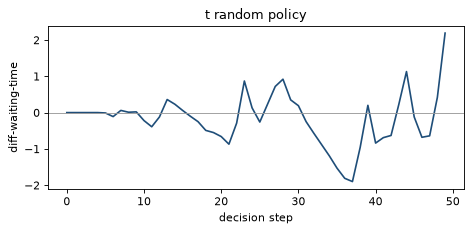

In [11]:
env = make_env("single", seed=0, additional_sumo_cmd="--no-step-log")
rewards = []
try:
    _obs, _info = env.reset(seed=0)
    agent = env.agents[0]
    for _ in range(50):
        if not env.agents:
            break
        actions = {a: env.action_space(a).sample() for a in env.agents}
        _obs, rew, _term, trunc, _info = env.step(actions)
        rewards.append(float(rew[agent]))
        if episode_finished(trunc):
            break
finally:
    env.close()

print(f"{agent}: 50-step mean reward {np.mean(rewards):.4f}, min {np.min(rewards):.4f}, max {np.max(rewards):.4f}")
fig, ax = plt.subplots()
ax.plot(rewards, color="#1f4e79")
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xlabel("decision step")
ax.set_ylabel("diff-waiting-time")
ax.set_title(f"{agent} random policy")
fig.tight_layout()
plt.show()

## 6. Neighbor graphs

`build_neighbor_map` links a signal to another controlled traffic light at the far end of an incoming edge (upstream) or an outgoing edge (downstream), then makes the relation symmetric. On `grid4x4` that is the 4-by-4 road grid: corners have 2 neighbors, edge signals 3, and inner signals 4. `cologne8` uses the same rule. Several of its signals have an empty neighbor list because an uncontrolled junction sits on the road between them.

cologne8 neighbor map
  26110729: ['247379907']
  247379907: ['26110729', 'cluster_1098574052_1098574061_247379905']
  256201389: []
  cluster_1098574052_1098574061_247379905: ['247379907']
  252017285: []
  280120513: []
  32319828: []
  62426694: []
grid4x4: 24 edges


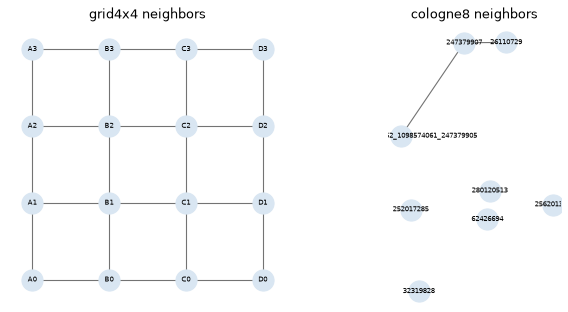

In [13]:
from pathlib import Path

import networkx as nx
import sumo_rl
import sumolib

from src.envs.neighbors import build_neighbor_map

_RESCO = Path(sumo_rl.__file__).resolve().parent / "nets" / "RESCO"


def _draw_neighbors(ax, net_file: str, ts_ids: list[str], title: str) -> dict[str, list[str]]:
    neighbor_map = build_neighbor_map(net_file, ts_ids)
    net = sumolib.net.readNet(net_file)
    graph = nx.Graph()
    graph.add_nodes_from(ts_ids)
    for signal, neighbors in neighbor_map.items():
        for other in neighbors:
            graph.add_edge(signal, other)
    positions = {signal: net.getNode(signal).getCoord() for signal in ts_ids}
    nx.draw(
        graph,
        positions,
        ax=ax,
        with_labels=True,
        node_color="#d9e6f2",
        node_size=360,
        font_size=6,
        edge_color="0.45",
    )
    ax.set_aspect("equal")
    ax.set_title(title)
    return neighbor_map


grid_ids = [f"{column}{row}" for column in "ABCD" for row in range(4)]
cologne_net = sumolib.net.readNet(str(_RESCO / "cologne8" / "cologne8.net.xml"))
cologne_ids = [tls.getID() for tls in cologne_net.getTrafficLights()]

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
grid_map = _draw_neighbors(axes[0], str(_RESCO / "grid4x4" / "grid4x4.net.xml"), grid_ids, "grid4x4 neighbors")
cologne_map = _draw_neighbors(axes[1], str(_RESCO / "cologne8" / "cologne8.net.xml"), cologne_ids, "cologne8 neighbors")
fig.tight_layout()
plt.show()

print("cologne8 neighbor map")
for signal, neighbors in cologne_map.items():
    print(f"  {signal}: {neighbors}")
print(f"grid4x4: {sum(len(neighbors) for neighbors in grid_map.values()) // 2} edges")

## 7. Episode timing and training budget

Wall-clock seconds for one 3600 s random episode of `single` and `grid4x4`, with TraCI and with `LIBSUMO_AS_TRACI=quiet`. Each run is a fresh process so the libsumo switch is applied before sumo-rl imports TraCI.

Projected CPU-hours use 7 methods (QL, DQN, PPO, and coordinated control at neighbor alpha 0, 0.25, 0.5, 0.75) and 5 train seeds. Episode budgets are 100 for `single`, 300 for `grid4x4`, and 200 for a RESCO network. RESCO is not timed here; its row reuses the `grid4x4` measurement. Training all three RESCO networks (`arterial4x4`, `cologne8`, `ingolstadt7`) at that budget triples the RESCO row.

In [15]:
import subprocess
import textwrap

import pandas as pd

EPISODE_SCRIPT = textwrap.dedent(
    """
    import os
    import time

    scenario = os.environ["SCENARIO"]
    if os.environ.get("USE_LIBSUMO") == "1":
        os.environ["LIBSUMO_AS_TRACI"] = "quiet"
    else:
        os.environ.pop("LIBSUMO_AS_TRACI", None)

    from src.envs.make_env import make_env

    env = make_env(scenario, seed=0, additional_sumo_cmd="--no-step-log --no-warnings")
    started = time.perf_counter()
    try:
        env.reset(seed=0)
        for _ in range(800):
            if not env.agents:
                break
            actions = {agent: env.action_space(agent).sample() for agent in env.agents}
            _obs, _rew, _term, trunc, _info = env.step(actions)
            if isinstance(trunc, dict) and trunc and all(trunc.values()):
                break
        else:
            raise SystemExit("episode did not finish within 800 decisions")
    finally:
        env.close()
    import traci
    impl = "libsumo" if type(traci.simulation).__module__ == "builtins" else "traci"
    print(f"IMPL {impl}")
    print(f"ELAPSED {time.perf_counter() - started:.3f}")
    """
)


def time_episode(scenario, use_libsumo):
    child_env = os.environ.copy()
    child_env["SUMO_HOME"] = os.environ["SUMO_HOME"]
    child_env["SCENARIO"] = scenario
    child_env["USE_LIBSUMO"] = "1" if use_libsumo else "0"
    child_env.pop("LIBSUMO_AS_TRACI", None)
    completed = subprocess.run(
        [sys.executable, "-c", EPISODE_SCRIPT],
        cwd=ROOT,
        env=child_env,
        text=True,
        capture_output=True,
        check=False,
    )
    if completed.returncode != 0:
        raise RuntimeError(completed.stderr[-2000:] or completed.stdout[-2000:])
    impl = elapsed = None
    for line in completed.stdout.splitlines():
        if line.startswith("IMPL "):
            impl = line.split()[1]
        elif line.startswith("ELAPSED "):
            elapsed = float(line.split()[1])
    if impl is None or elapsed is None:
        raise RuntimeError(completed.stdout[-2000:])
    return impl, elapsed


rows = []
for scenario in ("single", "grid4x4"):
    for use_libsumo in (False, True):
        impl, elapsed = time_episode(scenario, use_libsumo)
        rows.append({"scenario": scenario, "requested": "libsumo" if use_libsumo else "traci", "impl": impl, "seconds": round(elapsed, 2)})
        print(f"{scenario:10} requested={rows[-1]['requested']:7} impl={impl:7} {elapsed:.2f} s")

timing = pd.DataFrame(rows)
print(timing.to_string(index=False))

N_METHODS = 7
N_SEEDS = 5
budgets = {"single": 100, "grid4x4": 300, "RESCO": 200}
print("\nProjected CPU-hours = 7 methods x 5 seeds x episodes x seconds/3600")
print("RESCO seconds/episode are the grid4x4 measurement, not a separate run.")
for requested in ("traci", "libsumo"):
    print(f"\n{requested}")
    total = 0.0
    by_scenario = {row.scenario: row.seconds for row in timing.itertuples() if row.requested == requested}
    for name, episodes in budgets.items():
        seconds = by_scenario["grid4x4"] if name == "RESCO" else by_scenario[name]
        hours = N_METHODS * N_SEEDS * episodes * seconds / 3600.0
        total += hours
        print(f"  {name:8} {episodes:3} episodes  {seconds:7.2f} s/ep  {hours:8.2f} CPU-h")
    print(f"  {'total':8} {'':14} {total:8.2f} CPU-h")
    print(f"  three RESCO networks at 200 episodes: {3 * N_METHODS * N_SEEDS * 200 * by_scenario['grid4x4'] / 3600.0:.2f} CPU-h instead of the single RESCO row")

single     requested=traci   impl=traci   8.44 s
single     requested=libsumo impl=libsumo 0.52 s
grid4x4    requested=traci   impl=traci   55.58 s
grid4x4    requested=libsumo impl=libsumo 2.64 s
scenario requested    impl  seconds
  single     traci   traci     8.44
  single   libsumo libsumo     0.52
 grid4x4     traci   traci    55.58
 grid4x4   libsumo libsumo     2.64

Projected CPU-hours = 7 methods x 5 seeds x episodes x seconds/3600
RESCO seconds/episode are the grid4x4 measurement, not a separate run.

traci
  single   100 episodes     8.44 s/ep      8.21 CPU-h
  grid4x4  300 episodes    55.58 s/ep    162.11 CPU-h
  RESCO    200 episodes    55.58 s/ep    108.07 CPU-h
  total                     278.39 CPU-h
  three RESCO networks at 200 episodes: 324.22 CPU-h instead of the single RESCO row

libsumo
  single   100 episodes     0.52 s/ep      0.51 CPU-h
  grid4x4  300 episodes     2.64 s/ep      7.70 CPU-h
  RESCO    200 episodes     2.64 s/ep      5.13 CPU-h
  total          